<a href="https://colab.research.google.com/github/ElSkart7/Animal-Classification/blob/main/notebooks/%20Animal_Classification_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Name: Animals-10
Source Hugging Face
Repository: Rapidata/Animals-10
Number of Classes: 10

In [18]:
# @title
!pip install -q datasets pillow pandas matplotlib

In [19]:
import numpy as np
from google.colab import drive
import os
import gc
from collections import Counter
from PIL import Image
from sklearn.model_selection import train_test_split

In [20]:
# @title
from datasets import load_dataset

dataset = load_dataset("Rapidata/Animals-10")

In [21]:
# @title
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 23554
    })
})


In [22]:
# @title
labels = dataset["train"].features["label"].names
print(labels)

['Butterfly', 'Cat', 'Chicken', 'Cow', 'Dog', 'Elephant', 'Horse', 'Sheep', 'Spider', 'Squirrel']


In [23]:
# @title
from collections import Counter
label_counts = Counter(dataset["train"]["label"])
for label_id, count in sorted(label_counts.items()):
  class_name = labels[label_id]
  print(f"{class_name}: {count}")

Butterfly: 1603
Cat: 1199
Chicken: 2993
Cow: 1797
Dog: 4811
Elephant: 1037
Horse: 2598
Sheep: 1376
Spider: 4340
Squirrel: 1800


Class Distribution Analysis

In [24]:
# @title
import pandas as pd
total_images = sum(label_counts.values())
df = pd.DataFrame([
    {
        "Class":labels[label_id],
        "Images":count,
        "Percentage":round(count/total_images * 100,2)
    }
    for label_id,count in sorted(label_counts.items())
])
print("Total Images:",total_images)
display(df)

Total Images: 23554


,Class,Images,Percentage
0,Butterfly,1603,6.81
1,Cat,1199,5.09
2,Chicken,2993,12.71
3,Cow,1797,7.63
4,Dog,4811,20.43
5,Elephant,1037,4.40
6,Horse,2598,11.03
7,Sheep,1376,5.84
8,Spider,4340,18.43
9,Squirrel,1800,7.64


In [25]:
# @title
from collections import Counter
image_sizes = Counter()
for sample in dataset["train"]:
  image = sample["image"]
  image_sizes[image.size] +=1

print("different image dimensions:",len(image_sizes))
print("\nImage dimensions and their counts:")
for size,count in image_sizes.most_common():
  print(f"{size}:{count} images")

different image dimensions: 654

Image dimensions and their counts:
(300, 225):4276 images
(300, 200):3169 images
(300, 300):1170 images
(300, 169):1017 images
(300, 199):555 images
(225, 300):477 images
(300, 240):399 images
(300, 188):386 images
(200, 300):355 images
(300, 221):290 images
(300, 201):282 images
(300, 226):235 images
(300, 214):235 images
(300, 202):162 images
(201, 300):130 images
(300, 210):126 images
(300, 213):123 images
(300, 220):117 images
(300, 219):114 images
(300, 206):109 images
(300, 209):108 images
(226, 300):108 images
(300, 224):107 images
(169, 300):107 images
(300, 197):106 images
(300, 228):105 images
(300, 230):104 images
(300, 223):103 images
(300, 235):102 images
(300, 216):101 images
(300, 218):100 images
(300, 232):97 images
(300, 207):96 images
(300, 204):94 images
(300, 233):93 images
(300, 168):93 images
(300, 211):92 images
(300, 212):88 images
(300, 251):88 images
(300, 180):88 images
(300, 195):83 images
(300, 237):81 images
(300, 215):79 i

total images inspected: 23,554
number of different dimensions: 654
most commont dimensions:
1- 300 x 225: 4,276 images
2- 300 x 200: 3,169 images
3- 300 x 300: 1,170 images

conclusion:
dataset contains images with different dimensions so, image resziing will be required during preprocessing.

In [26]:
# @title
from PIL import Image
corrupted_images = []
for index, sample in enumerate(dataset["train"]):
  try:
    image = sample["image"]
    image.verify()
  except Exception:
    corrupted_images.append(index)
print("total corrupted images:" , len(corrupted_images))
print("total valid images:",len(dataset["train"])-len(corrupted_images))

total corrupted images: 0
total valid images: 23554


## 4. Dataset Exploration

### 4.1 Dataset Overview

The selected dataset is **Animals-10**, obtained from Hugging Face.

- **Dataset Source:** [Rapidata/Animals-10](https://huggingface.co/datasets/Rapidata/Animals-10)
- **Total Images:** 23,554
- **Number of Classes:** 10
- **Dataset Split:** Train (original dataset)

### 4.2 Dataset Classes

The dataset contains 10 animal categories:

1. Butterfly
2. Cat
3. Chicken
4. Cow
5. Dog
6. Elephant
7. Horse
8. Sheep
9. Spider
10. Squirrel

### 4.3 Class Distribution

The dataset contains different numbers of images for each class. Dog has the largest number of images (4,811), while Elephant has the smallest (1,037).

This indicates that the dataset has some class imbalance.

### 4.4 Image Dimensions

The dataset contains **654 different image dimensions**.

Images have varying widths and heights, so resizing will be required during preprocessing to ensure consistent input dimensions for the CNN model.

### 4.5 Data Quality Check

- **Valid Images:** 23,554
- **Corrupted Images:** 0

All images passed the image integrity check.


In [27]:
# @title
import pandas as pd
total_images = len(dataset["train"])
class_distribution = pd.DataFrame([
    {
        "Class":labels[label_id],
        "Images": count,
        "Percentage (%)": round(count/total_images*100,2)
    }
    for label_id,count in sorted(label_counts.items())
])
display(class_distribution)

,Class,Images,Percentage (%)
0,Butterfly,1603,6.81
1,Cat,1199,5.09
2,Chicken,2993,12.71
3,Cow,1797,7.63
4,Dog,4811,20.43
5,Elephant,1037,4.40
6,Horse,2598,11.03
7,Sheep,1376,5.84
8,Spider,4340,18.43
9,Squirrel,1800,7.64


### 4.6 Class Distribution Analysis

The dataset has an imbalanced class distribution.

- **Largest Class:** Dog (4,811 images — 20.43%).
- **Smallest Class:** Elephant (1,037 images — 4.40%).
- Dog has approximately 4.6 times more images than Elephant.

This imbalance may affect the model's ability to learn all classes equally. Therefore, class distribution should be considered during model training and evaluation.

## 5. Data Visualization
This section presents visualizations that help understand the Animals-10 dataset, including sample images, class distribution, and examples of image variations.

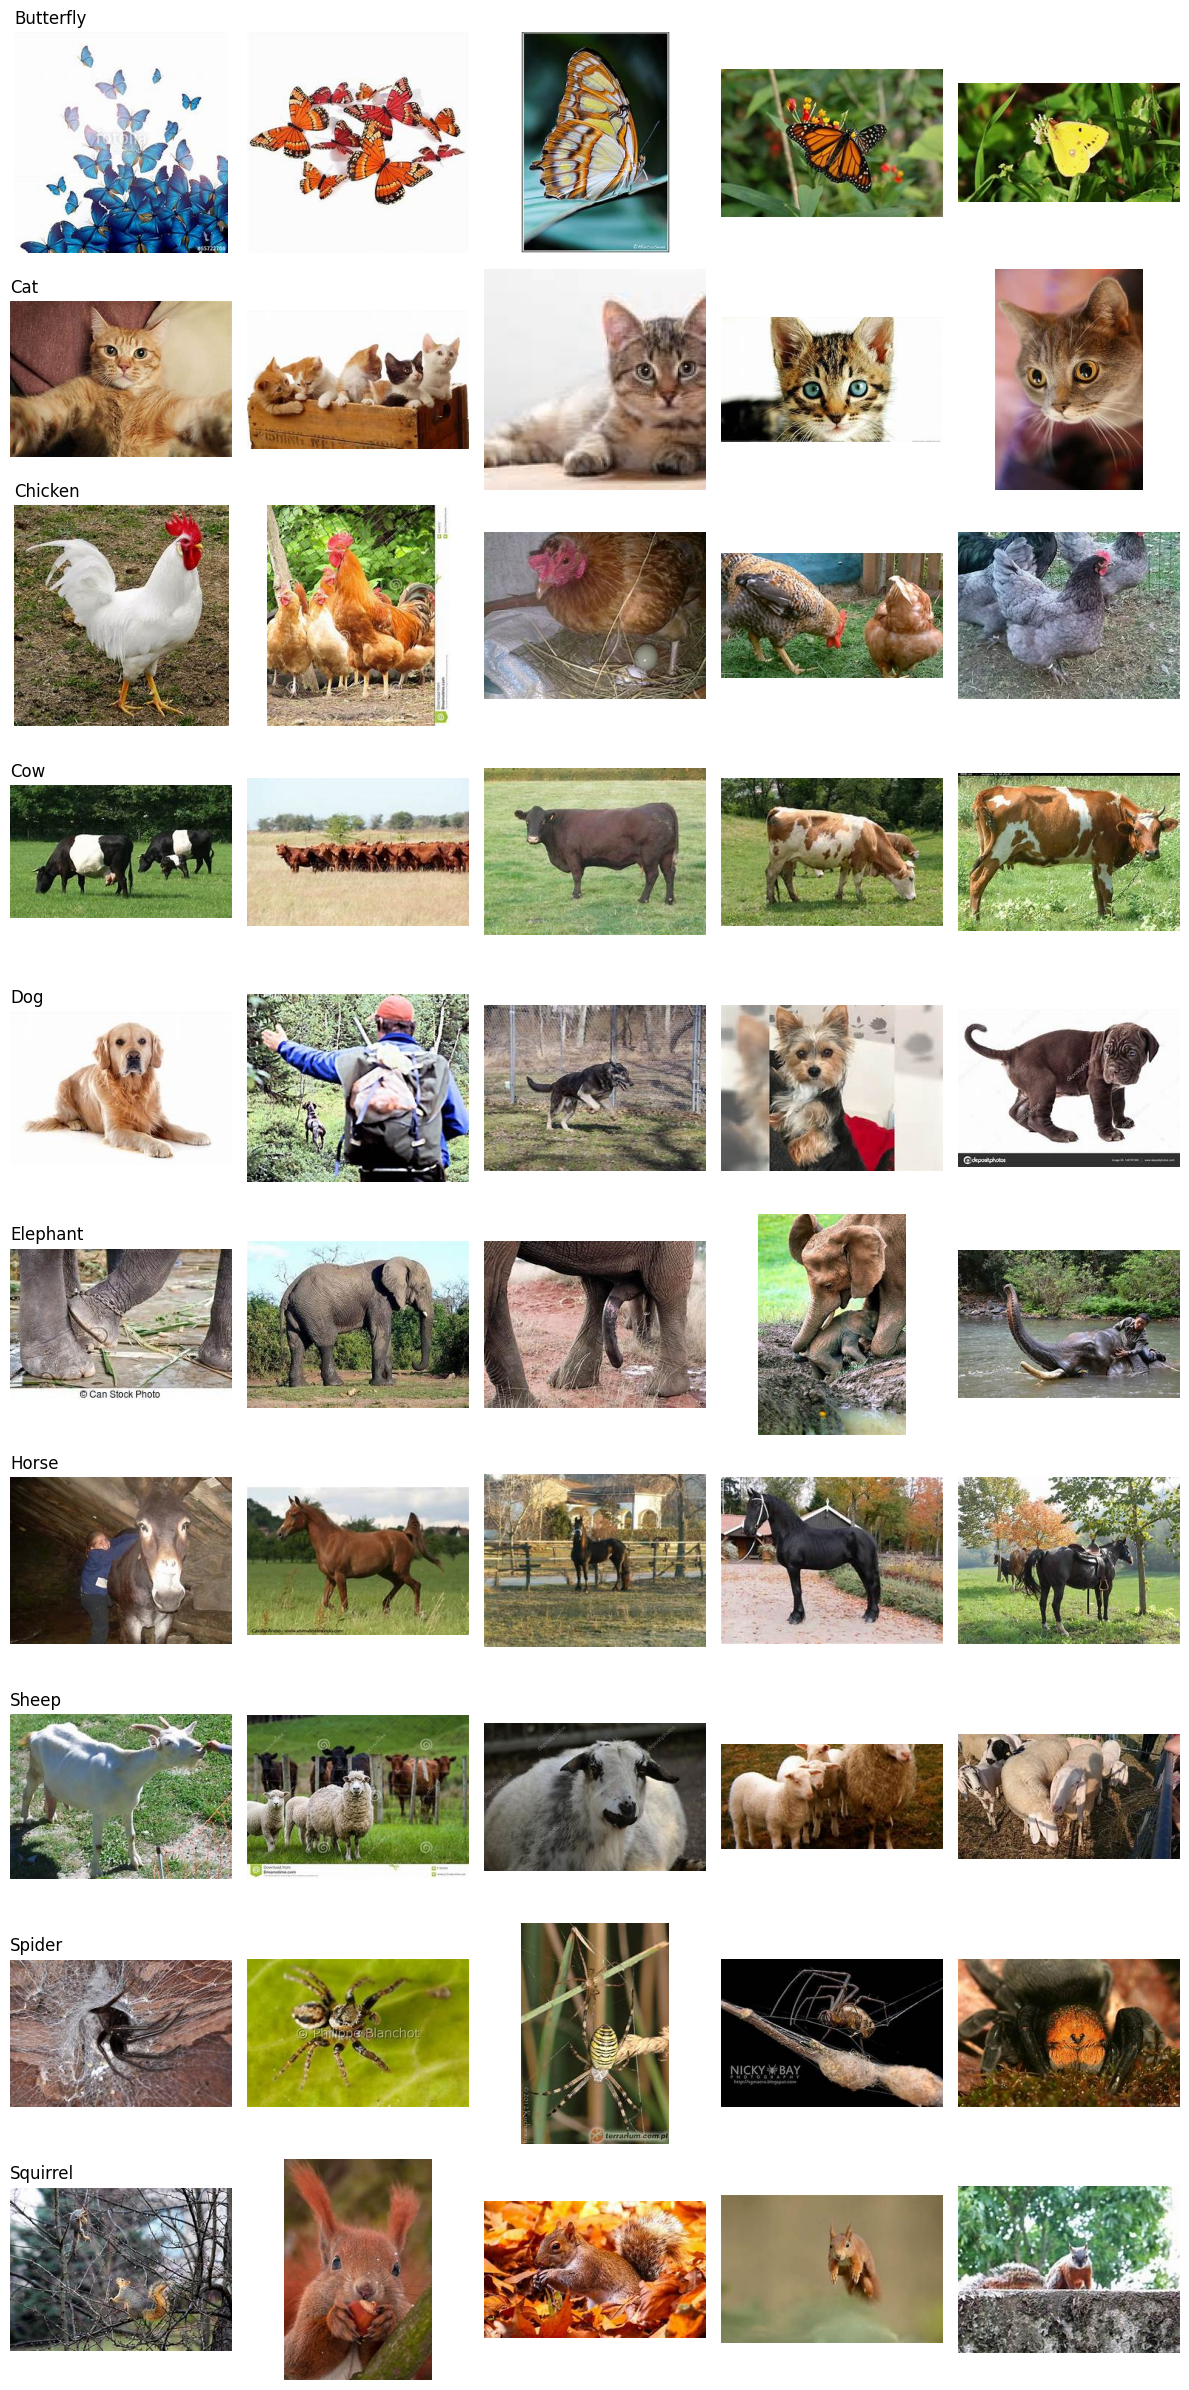

In [28]:
import matplotlib.pyplot as plt

labels = dataset["train"].features["label"].names
all_labels = dataset["train"]["label"]
n = 5

fig, axes = plt.subplots(10, n, figsize=(12, 24))
for class_id, class_name in enumerate(labels):
    idxs = [i for i, l in enumerate(all_labels) if l == class_id][:n]
    for j, idx in enumerate(idxs):
        axes[class_id, j].imshow(dataset["train"][idx]["image"])
        axes[class_id, j].axis("off")
        if j == 0:
            axes[class_id, j].set_title(class_name, loc="left")
plt.tight_layout()
plt.show()

### 5.1 Sample Images from Each Class

The grid shows 5 sample images from each of the 10 classes: Butterfly, Cat, Chicken, Cow, Dog, Elephant, Horse, Sheep, Spider, and Squirrel.

**Observations:**
- Images vary in background (grass, indoor, white studio, forest, water), lighting, and viewpoint (close-ups, full-body, groups).
- Some images contain more than one animal, or partial views of the animal (for example, only the legs of an elephant).
- Some images contain watermarks or text.
- A few samples may be mislabeled: the first Sheep image looks like a goat and the first Horse image looks like a donkey. This should be checked before training.

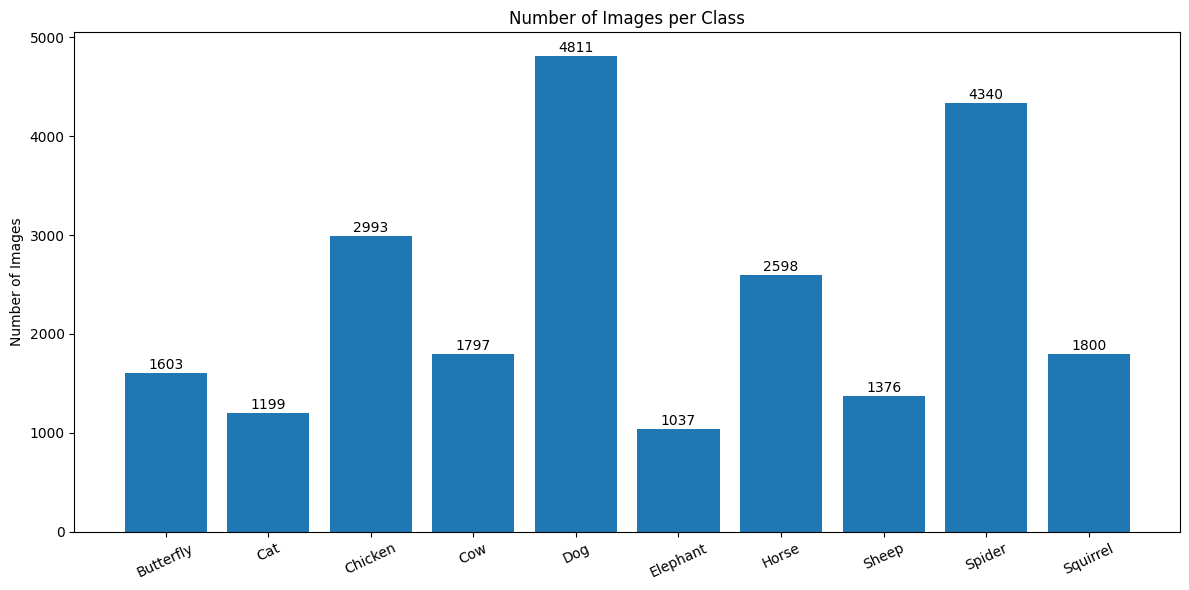

In [29]:
import matplotlib.pyplot as plt
from collections import Counter

labels = dataset["train"].features["label"].names
counts = Counter(dataset["train"]["label"])
names = [labels[i] for i in sorted(counts)]
values = [counts[i] for i in sorted(counts)]

plt.figure(figsize=(12, 6))
bars = plt.bar(names, values)
for bar, v in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width() / 2, v + 40, str(v), ha="center")
plt.title("Number of Images per Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

### 5.2 Number of Images per Class

The bar chart shows the number of images in each of the 10 classes (23,554 images in total).

- **Most images:** Dog (4,811) and Spider (4,340).
- **Fewest images:** Elephant (1,037), Cat (1,199), and Sheep (1,376).
- Dog has about 4.6 times more images than Elephant.
- The remaining classes (Chicken, Horse, Cow, Squirrel, Butterfly) fall in between, from about 1,600 to 3,000 images.

**Conclusion:** the dataset is imbalanced. The model may perform better on large classes (Dog, Spider) than on small ones (Elephant, Cat). This should be considered during training, for example by using class weights and by checking per-class accuracy.

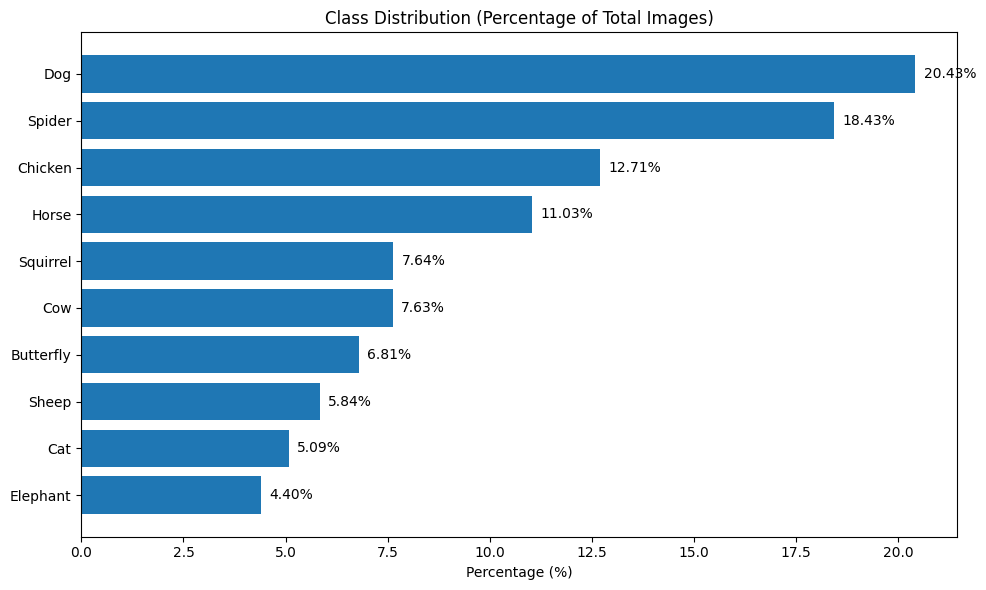

In [30]:
import matplotlib.pyplot as plt
from collections import Counter

labels = dataset["train"].features["label"].names
counts = Counter(dataset["train"]["label"])
total = sum(counts.values())

data = sorted(
    [(labels[i], c, c / total * 100) for i, c in counts.items()],
    key=lambda x: x[2],
)
names = [d[0] for d in data]
percents = [d[2] for d in data]

plt.figure(figsize=(10, 6))
bars = plt.barh(names, percents)
for bar, p in zip(bars, percents):
    plt.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height() / 2,
             f"{p:.2f}%", va="center")
plt.title("Class Distribution (Percentage of Total Images)")
plt.xlabel("Percentage (%)")
plt.tight_layout()
plt.show()

### 5.3 Class Distribution (Percentage)

The chart shows each class as a percentage of the 23,554 images.

- **Largest classes:** Dog (20.43%) and Spider (18.43%), which together make up about 39% of the dataset.
- **Smallest classes:** Cat (5.09%) and Elephant (4.40%).
- Dog has about 4.6 times more images than Elephant, so the dataset is imbalanced.

**Why this matters:** the model may learn the larger classes better than the smaller ones. This should be considered during training and evaluation (for example, by checking per-class results, not only overall accuracy).

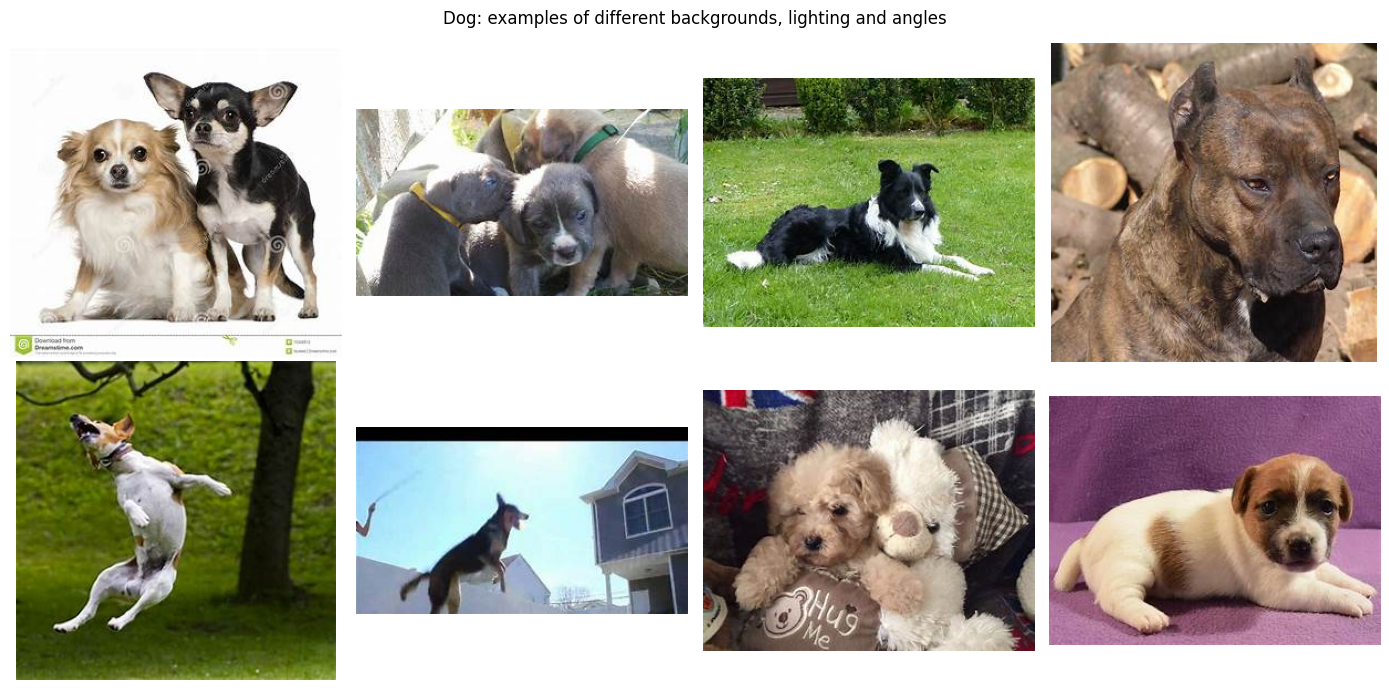

In [31]:
import random
import matplotlib.pyplot as plt

labels = dataset["train"].features["label"].names
all_labels = dataset["train"]["label"]

class_name = "Dog"
class_id = [l.lower() for l in labels].index(class_name.lower())
idxs = [i for i, l in enumerate(all_labels) if l == class_id]

random.seed(7)
picked = random.sample(idxs, 8)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, idx in zip(axes.flatten(), picked):
    ax.imshow(dataset["train"][idx]["image"])
    ax.axis("off")
plt.suptitle(f"{class_name}: examples of different backgrounds, lighting and angles")
plt.tight_layout()
plt.show()

### 5.4 Image Variations (Dog class)

The sample of Dog images shows large variation in the following:

- **Backgrounds:** plain white studio background, green grass, a wooden log pile, a purple blanket, indoor couch/toys, and an outdoor house with sky.
- **Lighting:** bright natural daylight outdoors, softer indoor lighting, and a studio-lit image.
- **Angles and poses:** close-up face, a dog lying down, a dog jumping in mid-air, and puppies seen from different sides.
- **Number of animals:** some images contain one dog, others contain two or more dogs, or a dog next to toys.
- **Breeds, sizes and colors:** different breeds with different coat colors (black/white, brown, cream, tan).
- **Image quality:** some images have watermarks, borders, or different aspect ratios.

**Why this matters:** This variety can help the CNN learn general features instead of memorizing specific backgrounds. However, it can also make classification more challenging. Data augmentation techniques (such as flipping, rotation, and zooming) may be used during preprocessing to introduce additional variation. Since the images have different dimensions (see Section 4.4), they must also be resized to a consistent input size before training.

# 6. Data Preprocessing
This section prepares the dataset for CNN training by splitting it into training, validation, and testing sets, resizing images to a consistent size, converting them to RGB format, and normalizing pixel values.

### 6.1 Label Mapping

Each animal class is assigned a unique numerical label. This mapping allows the CNN model to work with numerical class identifiers instead of text labels.

In [32]:
train_raw = dataset["train"]
class_names = list(train_raw.features["label"].names)

label2id = {name: idx for idx, name in enumerate(class_names)}
id2label = {idx: name for name, idx in label2id.items()}

print("Label mapping:")
print(label2id)

Label mapping:
{'Butterfly': 0, 'Cat': 1, 'Chicken': 2, 'Cow': 3, 'Dog': 4, 'Elephant': 5, 'Horse': 6, 'Sheep': 7, 'Spider': 8, 'Squirrel': 9}


### 6.2 Image Preprocessing Configuration

These settings define the target image dimensions, ensure reproducible data splitting, and control the number of images used during preprocessing.

In [33]:
IMG_SIZE = (128, 128)
RANDOM_STATE = 42
LIMIT = None

### 6.3 Preparing Labels and Dataset Indices

The labels are extracted from the dataset and converted into a NumPy array. Image indices are also created to identify the samples used during preprocessing. If a data limit is specified, only the selected number of images will be used.

In [34]:
# Extracting labels
y = np.array(train_raw["label"], dtype=np.int64)

# Creating image indices
indices = np.arange(len(y))

# Applying an optional data limit
if LIMIT is not None:
    indices = indices[:LIMIT]
    y = y[:LIMIT]

print("Working with", len(indices), "images")


Working with 23554 images


### 6.4 Train, Validation, and Test Split

The dataset is divided into three subsets: 70% for training, 15% for validation, and 15% for testing.

Stratified splitting is used to maintain approximately the same class distribution across all three subsets. Assertions are also used to verify that there is no overlap between the subsets and that all images are included.

In [35]:
# Split 70% for training and 30% for temporary data
idx_train, idx_temp = train_test_split(
    indices,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

# Split the remaining 30% equally into validation and test
idx_val, idx_test = train_test_split(
    idx_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y[idx_temp]
)

# Verify no overlap and full coverage
assert len(set(idx_train) & set(idx_val)) == 0
assert len(set(idx_train) & set(idx_test)) == 0
assert len(set(idx_val) & set(idx_test)) == 0

assert len(idx_train) + len(idx_val) + len(idx_test) == len(indices)

print("Train:", len(idx_train))
print("Validation:", len(idx_val))
print("Test:", len(idx_test))

# Display class distribution in each subset
for name, idx in [
    ("train", idx_train),
    ("validation", idx_val),
    ("test", idx_test)
]:
    counts = Counter(y[idx].tolist())
    print(name, {
        id2label[k]: counts[k]
        for k in sorted(counts)
    })

Train: 16487
Validation: 3533
Test: 3534
train {'Butterfly': 1122, 'Cat': 839, 'Chicken': 2095, 'Cow': 1258, 'Dog': 3368, 'Elephant': 726, 'Horse': 1818, 'Sheep': 963, 'Spider': 3038, 'Squirrel': 1260}
validation {'Butterfly': 240, 'Cat': 180, 'Chicken': 449, 'Cow': 269, 'Dog': 721, 'Elephant': 156, 'Horse': 390, 'Sheep': 207, 'Spider': 651, 'Squirrel': 270}
test {'Butterfly': 241, 'Cat': 180, 'Chicken': 449, 'Cow': 270, 'Dog': 722, 'Elephant': 155, 'Horse': 390, 'Sheep': 206, 'Spider': 651, 'Squirrel': 270}


In [36]:
drive.mount('/content/drive')

DATA_DIR = "/content/drive/MyDrive/Animal_Classification/prepared_data"

os.makedirs(DATA_DIR, exist_ok=True)

Mounted at /content/drive


### 6.5 Image Preprocessing and Saving

Each image is converted to RGB format and resized to 128×128 pixels to ensure consistent input dimensions. The processed images are stored as NumPy arrays using uint8 format to reduce memory usage. The images and their corresponding labels are saved separately for each dataset split.

In [37]:
os.makedirs("prepared_data", exist_ok=True)

def process_and_save(selected_indices, split_name):
    output_path = os.path.join(DATA_DIR, f"{split_name}.npy")

    # Create a fixed-size array
    images = np.lib.format.open_memmap(
        output_path,
        mode="w+",
        dtype=np.uint8,
        shape=(len(selected_indices), IMG_SIZE[0], IMG_SIZE[1], 3)
    )

    labels = y[selected_indices]

    for position, original_index in enumerate(selected_indices):
        image = train_raw[int(original_index)]["image"]
        image = image.convert("RGB")
        image = image.resize(IMG_SIZE, Image.Resampling.LANCZOS)

        images[position] = np.asarray(image, dtype=np.uint8)

        if (position + 1) % 500 == 0:
            print(split_name, position + 1, "/", len(selected_indices))

    images.flush()
    np.save(os.path.join(DATA_DIR, f"{split_name}_labels.npy"), labels)

    print("Saved:", split_name)

    del images
    gc.collect()


process_and_save(idx_train, "train")
process_and_save(idx_val, "validation")
process_and_save(idx_test, "test")

print("All datasets saved successfully!")

train 500 / 16487
train 1000 / 16487
train 1500 / 16487
train 2000 / 16487
train 2500 / 16487
train 3000 / 16487
train 3500 / 16487
train 4000 / 16487
train 4500 / 16487
train 5000 / 16487
train 5500 / 16487
train 6000 / 16487
train 6500 / 16487
train 7000 / 16487
train 7500 / 16487
train 8000 / 16487
train 8500 / 16487
train 9000 / 16487
train 9500 / 16487
train 10000 / 16487
train 10500 / 16487
train 11000 / 16487
train 11500 / 16487
train 12000 / 16487
train 12500 / 16487
train 13000 / 16487
train 13500 / 16487
train 14000 / 16487
train 14500 / 16487
train 15000 / 16487
train 15500 / 16487
train 16000 / 16487
Saved: train
validation 500 / 3533
validation 1000 / 3533
validation 1500 / 3533
validation 2000 / 3533
validation 2500 / 3533
validation 3000 / 3533
validation 3500 / 3533
Saved: validation
test 500 / 3534
test 1000 / 3534
test 1500 / 3534
test 2000 / 3534
test 2500 / 3534
test 3000 / 3534
test 3500 / 3534
Saved: test
All datasets saved successfully!


### 6.6 Batch Generator

A custom batch generator is implemented to load images in small batches instead of loading the entire dataset into memory. This helps reduce memory usage during model training.

The generator also converts image values from uint8 to float32 and normalizes pixel values to the range [0, 1]. Shuffling is applied to the training data after each epoch.

In [38]:
try:
    from tensorflow.keras.utils import Sequence as _BaseSequence
except ImportError:
    _BaseSequence = object


class SplitGenerator(_BaseSequence):

    def __init__(self, images_path, labels_path, batch_size=32, shuffle=False):
        self.images = np.load(images_path, mmap_mode="r")
        self.labels = np.load(labels_path)

        self.batch_size = batch_size
        self.shuffle = shuffle
        self.order = np.arange(len(self.labels))

        self.rng = np.random.default_rng(RANDOM_STATE)

        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.labels) / self.batch_size))

    def __getitem__(self, batch_index):
        start = batch_index * self.batch_size
        batch_ids = self.order[start:start + self.batch_size]

        batch_x = np.asarray(
            self.images[batch_ids], dtype=np.float32
        ) / 255.0

        batch_y = self.labels[batch_ids]

        return batch_x, batch_y

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.order)

In [39]:
BATCH_SIZE = 32

train_gen = SplitGenerator(
    os.path.join(DATA_DIR, "train.npy"),
    os.path.join(DATA_DIR, "train_labels.npy"),
    BATCH_SIZE,
    shuffle=True
)

val_gen = SplitGenerator(
    os.path.join(DATA_DIR, "validation.npy"),
    os.path.join(DATA_DIR, "validation_labels.npy"),
    BATCH_SIZE
)

test_gen = SplitGenerator(
    os.path.join(DATA_DIR, "test.npy"),
    os.path.join(DATA_DIR, "test_labels.npy"),
    BATCH_SIZE
)

print("Batches - train:", len(train_gen),
      "| validation:", len(val_gen),
      "| test:", len(test_gen))

print("Samples - train:", len(train_gen.labels),
      "| validation:", len(val_gen.labels),
      "| test:", len(test_gen.labels))

print("Image shape per sample:", train_gen.images.shape[1:])

Batches - train: 516 | validation: 111 | test: 111
Samples - train: 16487 | validation: 3533 | test: 3534
Image shape per sample: (128, 128, 3)


In [40]:
# Normalize in [0, 1]
X_batch, y_batch = train_gen[0]

print("One batch:", X_batch.shape, y_batch.shape, X_batch.dtype)

assert X_batch.min() >= 0
assert X_batch.max() <= 1
assert np.isfinite(X_batch).all()

print("Normalization check passed: batches come out in [0, 1]")

One batch: (32, 128, 128, 3) (32,) float32
Normalization check passed: batches come out in [0, 1]


### 6.7 Preprocessing Verification

The preprocessing pipeline was successfully executed and verified. All images were resized to 128×128 pixels and converted to RGB format. The dataset was divided into training, validation, and testing subsets with a 70/15/15 ratio.

The batch generator successfully loaded images in batches, and pixel values were normalized to the range [0, 1]. All validation checks passed successfully.

#### Before and After Preprocessing

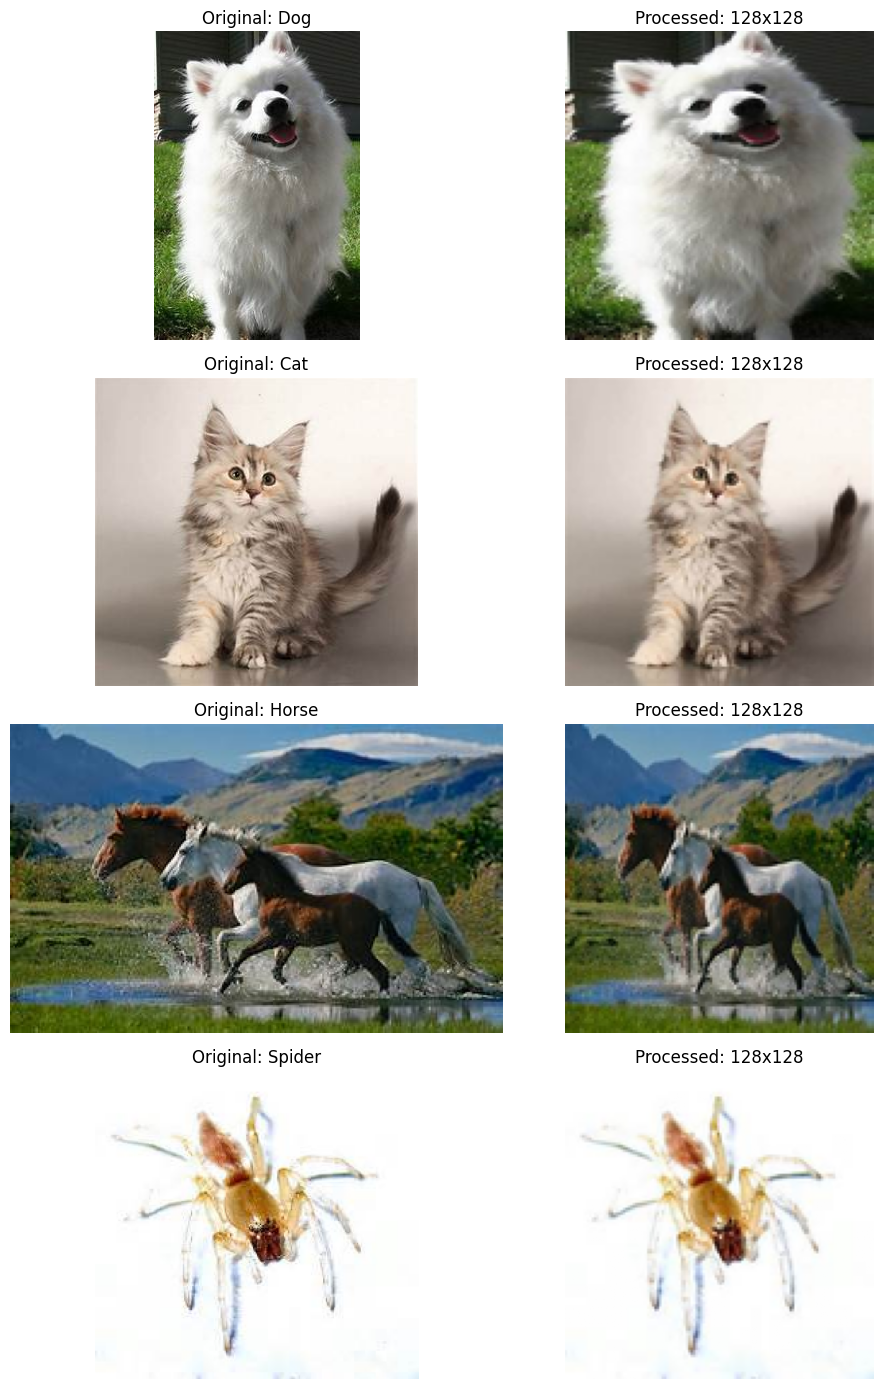

In [42]:
rng = np.random.default_rng(RANDOM_STATE)
sample_indices = rng.choice(len(indices), size=4, replace=False)

fig, axes = plt.subplots(4, 2, figsize=(10, 14))

for row, idx in enumerate(sample_indices):
    global_idx = int(indices[idx])
    label_name = id2label[int(y[idx])]

    # original image
    original_img = train_raw[global_idx]["image"]
    axes[row, 0].imshow(original_img)
    axes[row, 0].set_title(f"Original: {label_name}")
    axes[row, 0].axis("off")

    # processed image
    processed = np.asarray(
        original_img.convert("RGB").resize(IMG_SIZE, Image.Resampling.LANCZOS),
        dtype=np.float32
    ) / 255.0
    axes[row, 1].imshow(processed)
    axes[row, 1].set_title(f"Processed: {IMG_SIZE[0]}x{IMG_SIZE[1]}")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

## Notes

1. **Image Format & Size:** All images are converted to RGB format and resized to a fixed size of 128 × 128 pixels.

2. **Dataset Splitting:** The dataset is divided into three subsets:
   - 70% Training Set
   - 15% Validation Set
   - 15% Test Set

   Stratified splitting is used to maintain the class distribution across all subsets. The random state is set to `42` to ensure reproducibility.

3. **Label Mapping:** Each numerical label corresponds to a specific animal class. The mapping between label numbers and animal names is obtained from the `label2id` and `id2label` dictionaries.

4. **Data Type & Normalization:** Processed images are stored as `uint8` to reduce storage and memory usage. The data generator converts image batches to `float32` and normalizes pixel values to the range [0, 1]. Therefore, no additional normalization is required before passing batches to the model.